# Lesson 12. Giving a soft sphere axes of its own

[Course plan](../../README.md)

The point from the last lesson has no width. From any camera position it gives one address. Now we can surround it with a soft cloud. Joining places of equal weight around a round cloud gives a sphere. Stretching it in one direction and turning the whole cloud carries that same weight onto the surface of an ellipsoid.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. Three sizes for one cloud

Both views show a single wire surface. On the right we look along $z$, on the left from an angle. These are drawings without perspective for now. Three colored segments reach the surface along its own axes. The orange segment starts at 2 m, green at 0.75 m and purple at 1 m. Changing the angle moves their tips while preserving their lengths.

Three equal scales give a sphere. A turn through any angle moves the colored segments but leaves the geometric outline unchanged. With one axis longer, only some turns preserve the silhouette. The weight at the dark probe lets us tell those cases apart with a single number.

In [2]:
display(demos.geometry_lab(12, "en"))

The dark probe has a different job. It can move along the world $x$ axis independently of the shell's rotation. At $(1.5,0,0)$ m and zero angle the long axis runs right through the probe, putting it inside the mesh. A quarter turn later the short axis runs through the same point and the mesh falls short of it. The colored segment belongs to the shape. The dark mark belongs to the table. Turning the shape changes its weight at a fixed place in space, and the new weight is something we can predict.

## 2. Routes out from the center

A round cloud starts with all three scales equal to one metre. Moving one metre right, one metre down or one metre forward describes three different trips, **each starting at the center**. Each destination has the same weight. A fourth trip goes 0.6 m right and then 0.8 m down. Its final distance from center is $\sqrt{0.6^2+0.8^2}=1$ m. The same sphere passes through all four endpoints. The path taken on the trip never enters the weight calculation; its endpoint does.

Suppose the cloud stretches to twice its width along $x$. A mark attached to the surface at $(1,0,0)$ moves to $(2,0,0)$. But the old, fixed table location $(1,0,0)$ is now just $1/2$ of a scale from the center. The same place on the table has moved inward in units of the new width. Along $y$ the opposite change shrinks the scale to $0.75$ m. One unit of that axis's own scale now runs out before a metre on the ruler does. Along $z$ we keep the original metre. A weight at an arbitrary point will now take three different divisions.

## 3. Computing a weight and drawing a shell

For now the axes line up with the world's. The center is $\mu=(0,0,0)$ m and scales are $s_x=2$, $s_y=0.75$, $s_z=1$ m. Along each axis we subtract the center and divide by **that axis's** scale. At $(2,0,0)$ we get $(2/2,0/0.75,0/1)=(1,0,0)$ with no units left. At $(0,0.75,0)$ we get $(0,1,0)$. The squares sum to 1 in both cases. Thus the weight from lesson 3 agrees even though the distances in meters differ:

$$
D^2=h_x^2+h_y^2+h_z^2,\qquad G=\exp(-D^2/2)=\exp(-1/2)\approx0.607.
$$

Here $h$ holds three relative displacements. $D^2$ measures squared distance on the cloud's own scales, and $G$ is a relative weight peaking at 1 in the center. The wire drawing connects only places where $D^2=1$. Weight keeps falling beyond the wire. The cloud has no hard boundary there.

To draw the surface we can reverse the calculation. The unit sphere contains $h=(0.6,0.8,0)$ because $0.6^2+0.8^2=1$. Scaling along local axes gives $(1.2,0.6,0)$ m. Rotation $R$ comes next, followed by the addition of the center. The short expression $P=\mu+RSh$ uses the diagonal matrix $S$. Its diagonal holds the three scales and every other entry is zero. Multiplying by it gives exactly $(s_x h_x,s_y h_y,s_z h_z)$.

In [3]:
scales = np.array([2., .75, 1.])
h = np.array([.6, .8, 0.])
print("Sh =", scales*h, "m; G =", np.exp(-(h @ h)/2))
assert np.isclose(h @ h, 1)

Sh = [1.2 0.6 0. ] m; G = 0.6065306597126334


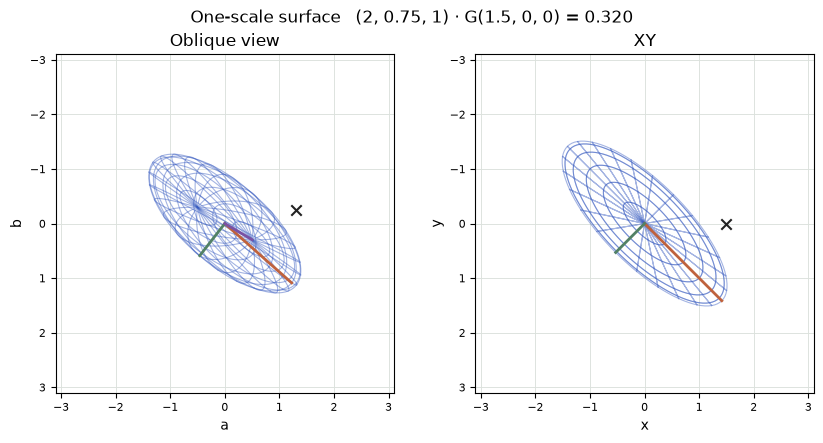

In [4]:
fig = demos.ellipsoid_figure("en")
plt.show()

## 4. A fixed probe and two directions through the calculation

Suppose the shape already has a rotation $R$ and its center has moved to $\mu=(3,-1,4)$ m. When drawing a mesh, we know a point on the unit sphere and want its world address. The point first stretches along its own axes, then rotates, then acquires the translation of the center. For example, $h=(0.6,0.8,0)$ stretched to $(1.2,0.6,0)$. A $90^\circ$ turn about $z$ sends the long axis to $+y$ and the old downward axis to $-x$. The offset becomes $(-0.6,1.2,0)$. Translation then places the point at $(2.4,0.2,4)$ m in the world.

When drawing an image the question often runs the **opposite way**. We already know the world point $P=(2.4,0.2,4)$. How close to the center is it, in Gaussian units? Subtracting $\mu$ recovers $(-0.6,1.2,0)$. Undoing the rotation recovers $(1.2,0.6,0)$ in the shape's own axes. Only now do we divide by $(2,0.75,1)$, obtaining $(0.6,0.8,0)$. The squared entries again sum to one. Dividing the world-horizontal offset by the long scale of 2 straight away would keep the calculation horizontal as the drawing turned.

The dark probe exposes this mistake without moving the center. With $\mu=(0,0,0)$ and $P=(1.5,0,0)$, zero angle gives $D^2=(1.5/2)^2=0.5625$ and weight $\exp(-0.5625/2)\approx0.755$. At $90^\circ$ the local offset becomes $(0,-1.5,0)$. Now $D^2=(-1.5/0.75)^2=4$ and the weight is $\exp(-2)\approx0.135$. The metre ruler reads 1.5 from probe to center in both cases. What changed is the width lying along that distance. A sphere with three matching scales would keep a flat weight trace through any rotation.

In [5]:
mark = np.array([1.5, 0., 0.])
for degrees in [0, 45, 90]:
    q = geo.axis_angle_quaternion([0,0,1], degrees)
    local = geo.quaternion_matrix(q).T @ mark
    h_probe = local / scales
    d2 = h_probe @ h_probe
    cov = geo.covariance_3d(scales, q)
    np.testing.assert_allclose(d2, mark @ np.linalg.solve(cov, mark))
    print(f"{degrees:2}°  local = {np.round(local,4)}  D² = {d2:.4f}  G = {np.exp(-d2/2):.4f}")

 0°  local = [1.5 0.  0. ]  D² = 0.5625  G = 0.7548
45°  local = [ 1.0607 -1.0607  0.    ]  D² = 2.2813  G = 0.3196
90°  local = [ 0.  -1.5  0. ]  D² = 4.0000  G = 0.1353


## 5. An axis, an angle and four rotation numbers

A rotation axis is an arrow that stays put during the turn. A $90^\circ$ turn about $z$ takes right $(1,0,0)$ to down $(0,1,0)$. The three columns of $R$ are the new locations of the old axes. For this turn they are $(0,1,0)$, $(-1,0,0)$ and $(0,0,1)$. That already suffices to apply $R$ to any point.

A **quaternion** stores a rotation in four numbers, handy when fitting the rotation during learning. Our order is $q=(w,x,y,z)$ with the scalar first. These $x,y,z$ belong to the rotation record and do not locate the center. If the axis is given by arrow $a=(0,0,2)$, we first divide by its length $\sqrt{0^2+0^2+2^2}=2$. That gives unit axis $n=(0,0,1)$. A zero arrow has no direction. Axis and angle $\theta$ give

$$
w=\cos(\theta/2),\qquad (x,y,z)=n\sin(\theta/2).
$$

For $\theta=90^\circ$ the half angle is $45^\circ$. Both cosine and sine are $\sqrt{2}/2\approx0.7071$. This gives $q=(0.7071,0,0,0.7071)$. Its four squared entries add up to 1. If learning supplies $(2,0,0,2)$, we first divide every component by the length $\sqrt{2^2+2^2}=\sqrt{8}$. That recovers the same unit quaternion. For $(0,0,0,0)$ the division is undefined.

Why half the angle? For a turn about $z$, the rightward unit arrow becomes $(w^2-z^2,\,2wz,\,0)$. Writing $w=\cos t$ and $z=\sin t$ turns this into $(\cos(2t),\sin(2t),0)$ by the double-angle identities. It has already turned through $2t$. A turn through $\theta$ therefore needs $t=\theta/2$ inside the representation. Our example gives $(0.5-0.5,\;2\cdot0.7071^2,\;0)\approx(0,1,0)$, just as in the drawing.

In [6]:
q = geo.axis_angle_quaternion([0,0,2], 90)
R = geo.quaternion_matrix(q)
print("q =", q, "\nR =\n", R, "\nR (1,0,0) =", R @ [1,0,0])
np.testing.assert_allclose(R, geo.quaternion_matrix([2,0,0,2]), atol=1e-14)

q = [0.7071 0.     0.     0.7071] 
R =
 [[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]] 
R (1,0,0) = [0. 1. 0.]


## 6. Reading the entries of a rotation matrix

A rotation about $z$ mostly fits on a drawing of the $xy$ plane. How could we test the large matrix formula for a tilted axis? An axis of $(1,1,1)$ and a turn of $120^\circ$, one third of a revolution, give us a particularly tangible answer. This axis runs along the diagonal from one corner of a cube to the opposite one. Three edges leave that corner symmetrically about the diagonal. A third of a turn must cycle them. Finding which edge goes where gives a simple test for the meaning of four stored numbers.

The axis length is $\sqrt{3}$, so each unit-axis component is $1/\sqrt{3}$. Half the angle is $60^\circ$. Its cosine gives $w=1/2$, and its sine is $\sqrt{3}/2$. Every vector component therefore equals $(1/\sqrt{3})(\sqrt{3}/2)=1/2$. The four numbers $q=(0.5,0.5,0.5,0.5)$ are already normalized, with squared length $4\cdot0.25=1$. Every pairwise product is $0.25$, so the formula below can be evaluated exactly.

Working down the first column, the top entry is $1-2(0.25+0.25)=0$, the middle one is $2(0.25+0.25)=1$, and the bottom one is $2(0.25-0.25)=0$. Together they give the vector $(0,1,0)$. That is the new tip of the first unit axis. Column two gives $(0,0,1)$ and column three gives $(1,0,0)$. In particular a local offset of $(2,0,0)$ turns into the world offset $(0,2,0)$. The offset $(1,1,1)$ is unchanged by the cycle: it lies on the rotation axis. The cube can turn through $120^\circ$ while that one arrow stays perfectly still.

If a file stores its scalar component last, the example with four equal components will fail to reveal the permutation. The previous quarter turn about $z$ will catch it. For moving data between programs, a free arrow $(1,0,0)$ with a known expected direction makes a much stronger check than the picture of a round splat. A rotation inside a sphere can be completely wrong with no visible change in its outline.

The repeated squares in the matrix have a geometric origin. Take a unit rotation axis $n=(n_x,n_y,n_z)$ and a rightward arrow $e=(1,0,0)$. The length of its shadow along the axis is $e\cdot n=n_x$, so the part that stays put is $n_x n$. The remaining part $e-n_x n$ lies in the plane of the turn. Its motion in that plane is a circle. One component follows the original radius with a multiplier of $\cos\theta$. The other follows the perpendicular tangent with a multiplier of $\sin\theta$. For this particular arrow the tangent is $(0,n_z,-n_y)$, found by taking the cross product $n\times e$. This operation gives an arrow perpendicular to both inputs, with the sign for a positive rotation. When $n=(0,0,1)$ the tangent is indeed straight down, $(0,1,0)$.

The horizontal component of the turned arrow is now $n_x^2+(1-n_x^2)\cos\theta$. The tangent contributes zero horizontally. Using $1-n_x^2=n_y^2+n_z^2$ and $1-\cos\theta=2\sin^2(\theta/2)$ rewrites this as $1-2(n_y^2+n_z^2)\sin^2(\theta/2)$. The quaternion entries $y$ and $z$ already include the sine of the half angle. This leaves $1-2(y^2+z^2)$, exactly the top left entry of the matrix. Measuring the same turned arrow vertically gives the next row of that column. Starting with the down and forward unit arrows gives the other two columns.

In [7]:
q_cube = geo.axis_angle_quaternion([1,1,1],120)
R_cube = geo.quaternion_matrix(q_cube)
expected = [[0,0,1],[1,0,0],[0,1,0]]
print("q =", np.round(q_cube,4), "  R @ [2,0,0] =", np.round(R_cube @ [2,0,0],4))
np.testing.assert_allclose(R_cube, expected, atol=1e-14)
np.testing.assert_allclose(R_cube @ [1,1,1], [1,1,1])

q = [0.5 0.5 0.5 0.5]   R @ [2,0,0] = [ 0.  2. -0.]


## 7. From quaternion to shape matrix

For any unit quaternion the same rules give the three turned axes. The first row below contains their horizontal components. To find the horizontal coordinate of a rotated point, each entry in the row multiplies the matching point coordinate and the three products are added.

$$
R=\begin{bmatrix}
1-2(y^2+z^2)&2(xy-zw)&2(xz+yw)\\
2(xy+zw)&1-2(x^2+z^2)&2(yz-xw)\\
2(xz-yw)&2(yz+xw)&1-2(x^2+y^2)
\end{bmatrix}.
$$

Here $xy$ means $x\cdot y$. For $q=(\sqrt{2}/2,0,0,\sqrt{2}/2)$ the first entry is $1-2(0+1/2)=0$, the second is $2(0-1/2)=-1$ and the third is zero. The horizontal coordinate of the rotated point $(1.2,0.6,0)$ is therefore $0\cdot1.2-1\cdot0.6+0=-0.6$ m. Flipping all four signs of $q$ together leaves every square and pairwise product unchanged. Both $q$ and $-q$ describe the same rotation.

Axis scales are positive. In local axes their squares form the diagonal of the covariance, $D=\mathrm{diag}(4,0.5625,1)$ in m². This $D$ is a matrix, unlike the scalar $D^2$ used above to compute a weight. If $M=RS$ carries a unit sphere into the ellipsoid, its covariance changes on both sides: $\Sigma=MM^{\mathsf T}=RDR^{\mathsf T}$. The entry $\Sigma_{xy}$ is the dot product of the first two rows of $M$. It measures how the same local displacements contribute along both world axes.

For a $45^\circ$ turn about $z$, let $c=\cos45^\circ=s=\sin45^\circ$. The first two rows of $M$ are $(2c,-0.75s,0)$ and $(2s,0.75c,0)$. Hence $\Sigma_{xx}=4c^2+0.5625s^2=2.28125$, $\Sigma_{yy}=2.28125$, and $\Sigma_{xy}=4cs-0.5625sc=1.71875$ m². The elongation goes right and down together, giving a positive off-diagonal entry. At $90^\circ$ that entry vanishes and the two transverse squared scales simply swap.

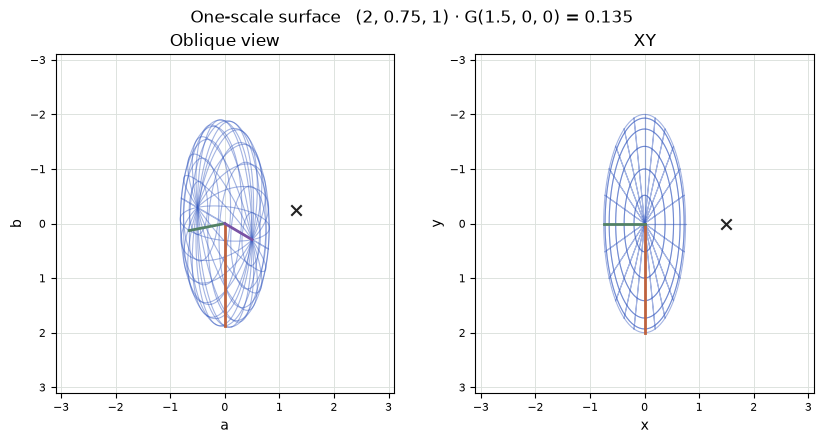

In [8]:
fig = demos.ellipsoid_figure("en", angle=90)
plt.show()

In [9]:
q45 = geo.axis_angle_quaternion([0,0,1], 45)
cov = geo.covariance_3d(scales, q45)
print("Σ =\n", cov)
delta = geo.quaternion_matrix(q45) @ (scales*h)
relative_squared = delta @ np.linalg.solve(cov, delta)
print("G on shell =", np.exp(-relative_squared/2))
np.testing.assert_allclose(relative_squared, 1)

Σ =
 [[2.2812 1.7188 0.    ]
 [1.7188 2.2813 0.    ]
 [0.     0.     1.    ]]
G on shell = 0.6065306597126333


## 8. Reading a soft shape back from its matrix

In the $45^\circ$ example the two diagonal entries in the plane match. Has our drawing become circular? The off-diagonal entry reveals the answer. The diagonal is $a=2.28125$ and the cross term is $b=1.71875$ m². Acting on $(1,1)$ with the upper left square of the covariance gives $(a+b,b+a)=(4,4)$: both numbers grew fourfold. Acting on $(1,-1)$ gives $(a-b,b-a)=(0.5625,-0.5625)$, scaling the arrow by $0.5625$. The first direction runs along the long diagonal in the drawing and the second runs across it. Matrix multiplication kept their directions and scaled them by 4 and 0.5625, the squares of the original axis scales.

Here **eigendirection** and **eigenvalue** can be read off an actual ellipse. Dividing $(1,1,0)$ by $\sqrt{2}$ makes it a unit arrow. Applying the covariance matrix to that arrow produces the same arrow multiplied by 4 m². Its square root gives the semi-axis length, 2 m. For the crosswise arrow the result is $\sqrt{0.5625}=0.75$ m. The third direction $(0,0,1)$ carries an eigenvalue of $1$ m². For a sphere all three eigenvalues match. The finished shape then cannot tell us where its first local axis pointed during construction. Extra decimal places cannot recover an orientation from a perfectly round surface.

At $45^\circ$ the dark probe's local displacement is $(1.5/\sqrt{2},-1.5/\sqrt{2},0)$ m. Dividing along the axes and adding squared components gives

$$
D^2=\frac{1.5^2/2}{2^2}+\frac{1.5^2/2}{0.75^2}
=0.28125+2=2.28125.
$$

The result happens to match a diagonal entry numerically. $D^2$ is dimensionless while that matrix entry is in m²; moving the probe breaks the coincidence. The weight at this point is about $0.320$. In world coordinates the same quantity comes from $D^2=d^{\mathsf T}\Sigma^{-1}d$, where $d=P-\mu$. The inverse covariance accounts for the reciprocal **squared** widths along the shape's axes. The final dot product adds their contributions. In code we solve $\Sigma v=d$ for $v$ and then compute $d\cdot v$. This avoids building a separate inverse matrix.

## 9. Mesh, slice and opacity

The two maps show slices at two fixed depths through the same cloud. The first slice runs through the center at $z=0$. The second is at $z=1$ m, one scale away along the depth axis. At every point in the second slice, one extra unit enters $D^2$. Its entire map is therefore weaker by a factor of $\exp(-1/2)\approx0.607$. The center of the first slice had weight 1; the center of the second has weight 0.607. A common color scale makes the comparison possible. Stretching each drawing independently to its own maximum would make the two slices appear identical.

The value $G$ still does not give a pixel color by itself. A dense clod and a smoky patch might share the same shape across slices and differ in opacity. Even a faint splat has $G=1$ at its center. If we multiply this spatial profile by an amplitude of 0.3, its peak becomes 0.3. On the one-scale contour the value would be $0.3\cdot0.607\approx0.182$. The maps here evaluate a spatial weight at a known point. A camera looks down a ray with many depths along it. Turning a three-dimensional shape into its screen footprint gets its own treatment in the next lesson.

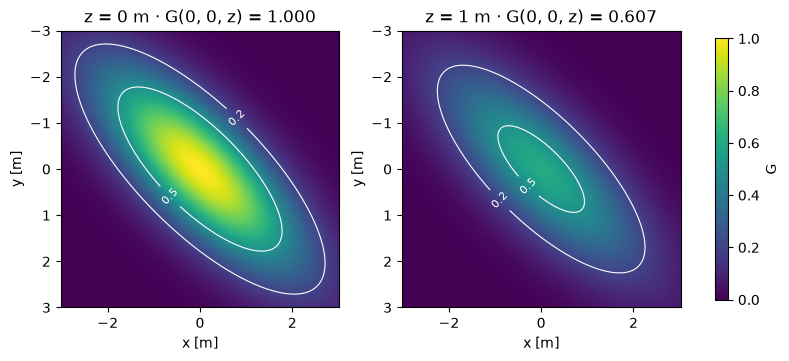

In [10]:
x, y = np.meshgrid(np.linspace(-3,3,151), np.linspace(-3,3,151))
fig, axes = plt.subplots(1,2,figsize=(7.8,3.6),layout="constrained")
rotation = geo.quaternion_matrix(q45)
for ax, z in zip(axes,[0.,1.]):
    offsets = np.stack([x, y, np.full_like(x,z)],axis=-1)
    local = offsets @ rotation
    weight = np.exp(-.5*np.sum((local/scales)**2,axis=-1))
    im = ax.pcolormesh(x,y,weight,shading="auto",vmin=0,vmax=1,cmap="viridis")
    contour = ax.contour(x,y,weight,levels=[.2,.5],colors="white",linewidths=.8)
    ax.clabel(contour,fmt="%.1f",fontsize=8)
    ax.set(xlabel="x [m]",ylabel="y [m]",title=f"z = {z:g} m · G(0, 0, z) = {weight[75,75]:.3f}",
           aspect="equal",ylim=(3,-3))
fig.colorbar(im,ax=list(axes),label="G",shrink=.8)
plt.show()

## 10. Where the geometry breaks

**An experiment.** An ellipsoid has scales $(2,1,1)$. First it turns about the long $x$ axis. In a separate experiment it turns about $z$. Which turn changes the silhouette viewed along $z$?

<details>
<summary>Working it out</summary>

For the first turn the two transverse sizes agree. Rotating their circle leaves the surface intact. The matrix remains $\mathrm{diag}(4,1,1)$. A $90^\circ$ turn about $z$ carries the long direction into $y$ and gives $\mathrm{diag}(1,4,1)$. The horizontal ellipse becomes vertical.

</details>

**A flat cloud.** What happens if $s_z=0$?

<details>
<summary>Working it out</summary>

The third displacement would have to be divided by zero. The shape matrix acquires a zero-width direction and can no longer recover the displacement along it. A flat disk has a geometry of its own, but a volumetric Gaussian weight needs three nonzero scales. Hence the experiment keeps the lower bound positive.

</details>

The same axis and half-angle representation appears in [SciPy's quaternion reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.from_quat.html). The location of the scalar component matters when exchanging rotation data.

## 11. Checking a shape with a handful of readings

**The other diagonal.** How could weight measurements at just two points distinguish $b=+1.71875$ from an off-diagonal entry of the same magnitude with negative sign?

<details>
<summary>Worked answer</summary>

Offsets $(1,1,0)$ and $(1,-1,0)$ will do. With positive $b$ the first mark lies along the long axis, so its relative distance is shorter and its weight higher. With negative $b$ the long axis runs toward the second mark. Readings on the world $x$ and $y$ axes alone do not show that difference.
</details>

**Is a positive diagonal enough?** One proposed planar covariance block has rows $(1,2)$ and $(2,1)$ in m². Which direction exposes the problem?

<details>
<summary>Worked answer</summary>

Multiplication by $(1,-1)$ gives $(-1,1)$, the same arrow scaled by $-1$. That would require a squared width of $-1$ m². No real positive width has such a square. Building the matrix from positive scales and a rotation automatically excludes this case.
</details>

**An invisible turn.** A cloud has scales $(2,2,0.5)$ m. How much will its weight at a fixed world point change after a $37^\circ$ turn about its own short axis?

<details>
<summary>Worked answer</summary>

The weight stays the same. The two squared displacements in the plane of the first axes each have denominator 4, so they enter as $(d_x^2+d_y^2)/4$. Rotation preserves that sum of squares, and the component along the rotation axis is unchanged. The weights cannot distinguish this turn from zero rotation.
</details>